# Few-Shot Learning — Relation Network (avec `easyfsl`)

Implémentation du **Relation Network** (Sung et al., 2018) en utilisant la librairie
[`easyfsl`](https://github.com/sicara/easy-few-shot-learning), un des 4 modèles metric-based
du projet de few-shot learning (les 3 autres — Siamese, Matching Network, ProtoNet — sont dans
des notebooks séparés, avec le même protocole d'évaluation pour pouvoir comparer les résultats
à la fin).

Architecture (comme sur le schéma fourni, figure originale de l'article) :

1. **Embedding module** $f_\varphi$ : un backbone convolutif encode chaque image (support et
   query) en une **carte de features** (feature map), pas un simple vecteur.
2. **Feature maps concatenation** : la feature map de la query est concaténée, canal par canal,
   avec celle de chaque classe de support (ou de chaque prototype de classe).
3. **Relation module** $g_\phi$ : un petit CNN appris qui prend cette concatenation et produit un
   **score de relation** entre 0 et 1 pour chaque paire (query, classe).
4. La classe prédite est celle dont le score de relation est maximal, comparé au **vecteur
   one-hot** cible.

**Point important pour le rapport / la soutenance** : contrairement aux 3 autres méthodes du
projet, le Relation Network **n'utilise pas la distance cosinus**. C'est précisément l'idée de
l'article : au lieu d'imposer une métrique fixe (cosinus, euclidienne...), on **apprend** la
fonction de comparaison $g_\phi$ avec un CNN entraînable. La "distance" devient donc un paramètre
appris plutôt qu'un choix a priori — c'est la principale différence conceptuelle à souligner face
au Pr. Khalfi.


## 1. Installation & imports

In [33]:
# easyfsl n'est pas installé par défaut sur Colab
!pip install easyfsl -q


In [34]:
import random

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as tud
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

# Correctif de compatibilité : certaines versions récentes de PyTorch ont retiré le paramètre
# `data_source` de `Sampler.__init__`, ce qu'easyfsl (1.5.0) utilise encore en interne dans
# `TaskSampler`. Ce patch neutralise l'appel sans rien changer au comportement du sampler.
_original_sampler_init = tud.Sampler.__init__
def _patched_sampler_init(self, *args, **kwargs):
    pass
tud.Sampler.__init__ = _patched_sampler_init

from easyfsl.samplers import TaskSampler
from easyfsl.datasets import WrapFewShotDataset
from easyfsl.methods import RelationNetworks
from easyfsl.utils import evaluate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)


Device : cuda


## 2. Chargement d'Omniglot

Même protocole que pour le Matching Network : split officiel de torchvision,
`background=True` (964 classes) pour l'entraînement épisodique, `background=False`
(659 classes jamais vues) pour l'évaluation.

Le ResNet18 attend des images à 3 canaux : on convertit donc les images Omniglot (1 canal, noir
sur blanc) en RGB et on les redimensionne en 84x84 (taille classique en few-shot learning).

`easyfsl.samplers.TaskSampler` a besoin d'un dataset qui implémente `get_labels()` (interface
`FewShotDataset`) : on utilise `easyfsl.datasets.WrapFewShotDataset`, qui enrobe n'importe quel
dataset PyTorch renvoyant `(image, label)`.

In [35]:
IMAGE_SIZE = 84

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

raw_train_dataset = datasets.Omniglot(root="./data", background=True, download=True, transform=transform)
raw_test_dataset = datasets.Omniglot(root="./data", background=False, download=True, transform=transform)

print("Train (background)  :", len(raw_train_dataset), "images")
print("Test  (evaluation)   :", len(raw_test_dataset), "images")


Train (background)  : 19280 images
Test  (evaluation)   : 13180 images


In [36]:
train_dataset = WrapFewShotDataset(raw_train_dataset)
test_dataset = WrapFewShotDataset(raw_test_dataset)


Scrolling dataset's labels...: 100%|██████████| 13180/13180 [00:11<00:00, 1190.55it/s]


## 3. Construction des épisodes (N-way, K-shot, Q-query)

`TaskSampler` échantillonne les épisodes : on l'utilise comme `batch_sampler` d'un `DataLoader`
classique, avec `episodic_collate_fn` comme fonction de collage.

In [37]:
def create_episodic_loader(dataset, n_way, k_shot, q_query, n_tasks, num_workers=2):
    sampler = TaskSampler(dataset, n_way=n_way, n_shot=k_shot, n_query=q_query, n_tasks=n_tasks)
    loader = DataLoader(
        dataset,
        batch_sampler=sampler,
        num_workers=num_workers,
        pin_memory=True,
        collate_fn=sampler.episodic_collate_fn,
    )
    return loader, sampler


In [38]:
# Test rapide
_, quick_sampler = create_episodic_loader(train_dataset, n_way=5, k_shot=1, q_query=5, n_tasks=1)
quick_loader = DataLoader(
    train_dataset,
    batch_sampler=quick_sampler,
    collate_fn=quick_sampler.episodic_collate_fn,
)

support_images, support_labels, query_images, query_labels, class_ids = next(iter(quick_loader))

print("Support :", support_images.shape, support_labels.shape)
print("Query   :", query_images.shape, query_labels.shape)
print("Classes de l'épisode :", class_ids)


Support : torch.Size([5, 3, 84, 84]) torch.Size([5])
Query   : torch.Size([25, 3, 84, 84]) torch.Size([25])
Classes de l'épisode : [281, 654, 114, 759, 25]


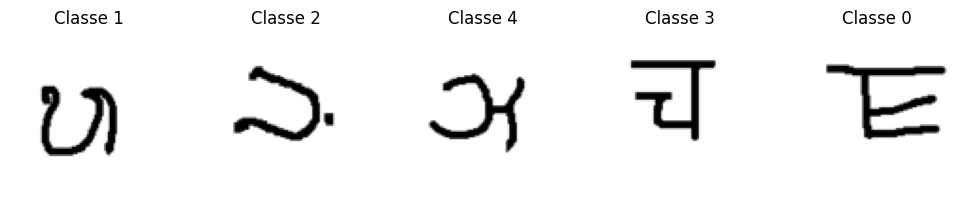

In [39]:
plt.figure(figsize=(10, 2))
for i in range(len(support_images)):
    plt.subplot(1, len(support_images), i + 1)
    # dénormalisation rapide pour l'affichage
    img = support_images[i].permute(1, 2, 0) * 0.5 + 0.5
    plt.imshow(img)
    plt.title(f"Classe {support_labels[i].item()}")
    plt.axis("off")
plt.tight_layout()
plt.show()


### Rappel — comment les classes d'un épisode sont choisies (question du prof)

Comme pour les 3 autres méthodes du projet, `TaskSampler` tire les `n_way` classes **uniformément
et sans remise** parmi toutes les classes du split (`random.sample(sorted(classes), n_way)`),
sans aucune notion de similarité visuelle ni de poids du réseau. Deux classes visuellement proches
(par ex. deux caractères du même alphabet) peuvent donc parfaitement se retrouver dans le même
épisode — voir le notebook du Matching Network pour la démonstration détaillée et le code source
commenté de `TaskSampler`.

## 4. Backbone : ResNet18 — en mode "feature map"

**Différence essentielle avec les 3 autres méthodes** : Matching Network, ProtoNet et Siamese Net
comparent des **vecteurs** d'embedding (d'où le `Flatten()` final sur le backbone). Le Relation
Network compare des **cartes de features** (feature maps) : le module de relation est lui-même un
CNN qui a besoin de la structure spatiale pour fonctionner (voir le schéma : les blocs violet/jaune
concaténés sont des feature maps, pas des vecteurs).

On retire donc `avgpool` **et** `fc` du ResNet18 (au lieu de remplacer seulement `fc` par un
`Flatten`), pour garder la sortie sous forme de carte `(canaux, hauteur, largeur)`. Avec des
images en entrée de 84x84, le ResNet18 tronqué produit des cartes de forme `(512, 3, 3)`.

In [40]:
def build_resnet18_feature_map_backbone(pretrained=False):
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    resnet18 = models.resnet18(weights=weights)
    # On retire les deux dernières couches (avgpool, fc) : la sortie reste une carte de features
    backbone = nn.Sequential(*list(resnet18.children())[:-2])
    feature_dimension = 512  # nombre de canaux en sortie de layer4
    return backbone, feature_dimension


backbone, FEATURE_DIMENSION = build_resnet18_feature_map_backbone(pretrained=False)

with torch.no_grad():
    sample_output = backbone(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE))
print("Forme de la carte de features en sortie du backbone :", sample_output.shape)


Forme de la carte de features en sortie du backbone : torch.Size([1, 512, 3, 3])


## 5. Relation Network

`easyfsl.methods.RelationNetworks` implémente le mécanisme complet de l'article original :

1. Extraction des cartes de features du support et de la query par le backbone (ResNet18 tronqué).
2. Calcul d'un **prototype par classe** (moyenne des cartes de features du support, comme pour
   ProtoNet) — `compute_prototypes`.
3. **Concatenation** : la carte de features de chaque query est concaténée (sur l'axe des canaux)
   avec chaque prototype de classe → `(n_query * n_way, 2 * feature_dimension, H, W)`.
4. **Module de relation** $g_\phi$ : un petit CNN (`Conv2d` + `BatchNorm` + `ReLU` +
   `AdaptiveMaxPool2d`, répété deux fois, puis deux couches `Linear`) qui transforme chaque paire
   concaténée en un score de relation dans $[0, 1]$ (sigmoïde finale).

$$r_{i,j} = g_\phi\big(\text{concat}(f_\varphi(x_j),\ \text{prototype}_i)\big) \in [0, 1]$$

**Loss** : contrairement aux autres méthodes (classification), Sung et al. traitent la sortie
comme un problème de **régression** vers le vecteur one-hot cible, et utilisent une **MSE loss**
(`nn.MSELoss`) plutôt qu'une cross-entropy / NLL.

In [41]:
relation_model = RelationNetworks(backbone, feature_dimension=FEATURE_DIMENSION).to(device)
print(relation_model)


RelationNetworks(
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_s

### 5.1 Entraînement

In [42]:
N_WAY = 5
K_SHOT = 1
Q_QUERY = 5
N_TRAINING_EPISODES = 1000

train_loader, _ = create_episodic_loader(
    train_dataset, n_way=N_WAY, k_shot=K_SHOT, q_query=Q_QUERY, n_tasks=N_TRAINING_EPISODES
)

relation_optimizer = optim.Adam(relation_model.parameters(), lr=1e-4)
criterion = nn.MSELoss()  # Relation Network -> régression vers le vecteur one-hot cible

relation_losses, relation_accuracies = [], []


In [43]:
def fit_on_episode(model, support_images, support_labels, query_images, query_labels, n_way, optimizer, criterion):
    model.train()
    optimizer.zero_grad()

    model.process_support_set(support_images.to(device), support_labels.to(device))
    relation_scores = model(query_images.to(device))

    query_labels = query_labels.to(device)
    one_hot_targets = nn.functional.one_hot(query_labels, n_way).float()
    loss = criterion(relation_scores, one_hot_targets)

    loss.backward()
    optimizer.step()

    predictions = torch.argmax(relation_scores, dim=1)
    accuracy = (predictions == query_labels).float().mean()

    return loss.item(), accuracy.item()


for episode_index, (support_images, support_labels, query_images, query_labels, _) in enumerate(train_loader):
    loss, accuracy = fit_on_episode(
        relation_model, support_images, support_labels, query_images, query_labels,
        N_WAY, relation_optimizer, criterion,
    )

    relation_losses.append(loss)
    relation_accuracies.append(accuracy)

    if (episode_index + 1) % 200 == 0:
        print(f"Episode [{episode_index+1}/{N_TRAINING_EPISODES}] "
              f"Loss: {np.mean(relation_losses[-200:]):.4f}  "
              f"Acc: {np.mean(relation_accuracies[-200:])*100:.2f}%")


Episode [200/1000] Loss: 0.1228  Acc: 54.80%
Episode [400/1000] Loss: 0.0947  Acc: 70.52%
Episode [600/1000] Loss: 0.0767  Acc: 78.36%
Episode [800/1000] Loss: 0.0603  Acc: 85.02%
Episode [1000/1000] Loss: 0.0511  Acc: 88.60%


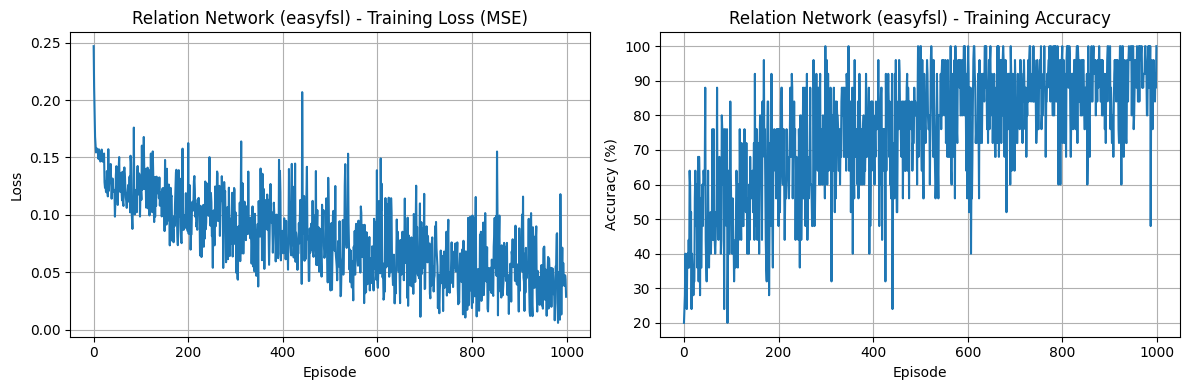

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(relation_losses)
axes[0].set_title("Relation Network (easyfsl) - Training Loss (MSE)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Loss")
axes[0].grid()

axes[1].plot([a * 100 for a in relation_accuracies])
axes[1].set_title("Relation Network (easyfsl) - Training Accuracy")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid()

plt.tight_layout()
plt.show()


### 5.2 Évaluation (5-way 1-shot / 5-way 5-shot)

In [45]:
N_EVAL_TASKS = 100
Q_QUERY_EVAL = 15

def evaluate_relation(model, dataset, n_way, k_shot, q_query=Q_QUERY_EVAL, n_tasks=N_EVAL_TASKS):
    loader, _ = create_episodic_loader(dataset, n_way=n_way, k_shot=k_shot, q_query=q_query, n_tasks=n_tasks)
    per_task_accuracies = []

    model.eval()
    with torch.no_grad():
        for support_images, support_labels, query_images, query_labels, _ in loader:
            model.process_support_set(support_images.to(device), support_labels.to(device))
            relation_scores = model(query_images.to(device))
            predictions = torch.argmax(relation_scores, dim=1)
            accuracy = (predictions == query_labels.to(device)).float().mean().item()
            per_task_accuracies.append(accuracy)

    return np.mean(per_task_accuracies), np.std(per_task_accuracies)


In [47]:
acc_1shot, std_1shot = evaluate_relation(relation_model, test_dataset, n_way=5, k_shot=1)
print(f"Relation Network - 5-way 1-shot : {acc_1shot*100:.2f}% +/- {std_1shot*100:.2f}%")

acc_5shot, std_5shot = evaluate_relation(relation_model, test_dataset, n_way=5, k_shot=5)
print(f"Relation Network - 5-way 5-shot : {acc_5shot*100:.2f}% +/- {std_5shot*100:.2f}%")


Relation Network - 5-way 1-shot : 84.79% +/- 9.85%
Relation Network - 5-way 5-shot : 90.88% +/- 5.67%


## 6. Évaluation étendue — 10-way (1-shot / 5-shot)

Comme dans les papiers de référence, on ne se limite pas à une seule configuration N-way K-shot.
On ajoute ici les deux configurations manquantes : **10-way 1-shot** et **10-way 5-shot** (le split
`test_dataset` d'Omniglot a 659 classes disponibles, on pourrait même aller au-delà du 10-way).

In [ ]:
acc_1shot_10way, std_1shot_10way = evaluate_relation(relation_model, test_dataset, n_way=10, k_shot=1)
print(f"Relation Network - 10-way 1-shot : {acc_1shot_10way*100:.2f}% +/- {std_1shot_10way*100:.2f}%")

acc_5shot_10way, std_5shot_10way = evaluate_relation(relation_model, test_dataset, n_way=10, k_shot=5)
print(f"Relation Network - 10-way 5-shot : {acc_5shot_10way*100:.2f}% +/- {std_5shot_10way*100:.2f}%")


### Tableau récapitulatif — Relation Network / easyfsl (4 configurations)

In [ ]:
import pandas as pd

relation_summary = pd.DataFrame([
    {"N-way": 5,  "K-shot": 1, "Accuracy (%)": f"{acc_1shot*100:.2f} \u00b1 {std_1shot*100:.2f}"},
    {"N-way": 5,  "K-shot": 5, "Accuracy (%)": f"{acc_5shot*100:.2f} \u00b1 {std_5shot*100:.2f}"},
    {"N-way": 10, "K-shot": 1, "Accuracy (%)": f"{acc_1shot_10way*100:.2f} \u00b1 {std_1shot_10way*100:.2f}"},
    {"N-way": 10, "K-shot": 5, "Accuracy (%)": f"{acc_5shot_10way*100:.2f} \u00b1 {std_5shot_10way*100:.2f}"},
])

relation_summary
